# 06 · Model selection and validation
**Owner:** P5 (Prediction Model & Monsoon Lift) · **Extends:** T25, T26

**Question.** Why were Ridge, Random Forest and XGBoost chosen, and how do we know the winner is really the best?

**Approach.**
1. Measure the traits of the data, using only days before the first forecast, and let them point to model families.
2. Compare the existing models with stronger baselines and new candidates.
3. Score **only real POS days**, with a rolling backtest in which every forecast uses only earlier days.
4. Test whether the differences are bigger than luck.
5. Apply a decision rule fixed before the results were seen.

**Decision rule.** A candidate replaces Ridge only if its MAE is lower, its Holm-adjusted Diebold-Mariano p-value is
below 0.05, **and** its 95% block-bootstrap interval for the MAE difference lies below zero. Otherwise Ridge stays.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import model_selection as ms, plotstyle, predict
plotstyle.apply()
C = plotstyle.C

ORDERS_CSV = ROOT / "data/raw/daily_orders.csv"
WEATHER_CSV = ROOT / "data/raw/weather.csv"
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)

## 1. Why synthetic days cannot be used for scoring
The generator draws each day independently, so synthetic days have realistic averages but no day-to-day memory.

In [2]:
full = predict.load_model_frame(WEATHER_CSV, ORDERS_CSV)
real = ms.load_real_frame(WEATHER_CSV, ORDERS_CSV)
flags = pd.read_csv(ORDERS_CSV, parse_dates=["date"]).set_index("date")["is_synthetic"]
y_all = full["order_count"]
groups = {"Real (Jan-Sep 2025)": y_all[flags == 0],
          "Synthetic 2024": y_all[(flags == 1) & (y_all.index.year == 2024)],
          "Synthetic Oct-Dec 2025": y_all[(flags == 1) & (y_all.index >= "2025-10-01")]}
memory = pd.DataFrame({name: {"days": len(s), "mean": s.mean(), "sd": s.std(), "acf_1_day": s.autocorr(1),
                              "acf_7_days": s.autocorr(7)} for name, s in groups.items()}).T
memory.round(3).to_csv(RESULTS / "selection_real_vs_synthetic.csv")
memory.round(3)

,days,mean,sd,acf_1_day,acf_7_days
Real (Jan-Sep 2025),272.0,197.868,33.031,0.767,0.645
Synthetic 2024,366.0,194.784,34.347,0.076,0.165
Synthetic Oct-Dec 2025,92.0,187.902,35.727,-0.016,-0.041


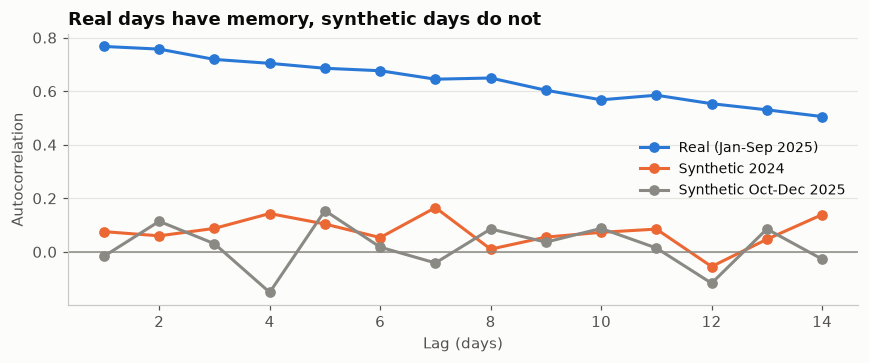

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
lags = range(1, 15)
for (name, s), color in zip(groups.items(), [C["blue"], C["orange"], C["gray"]]):
    ax.plot(lags, [s.autocorr(k) for k in lags], marker="o", color=color, label=name)
ax.axhline(0, color=C["gray"], lw=1); ax.set_xlabel("Lag (days)"); ax.set_ylabel("Autocorrelation")
ax.set_title("Real days have memory, synthetic days do not"); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "fig14_real_vs_synthetic_memory.png", dpi=150); plt.show()

## 2. Data profile: which traits point to which models
Measured only on the rows before the first forecast, so the test period does not influence the choice of models.

In [4]:
X = predict.make_features(real)
y = real["order_count"].loc[X.index]
first = ms.first_test_day(X)
Xpre, ypre = X[X.index < first], y[y.index < first]
print(f"Training rows before the first forecast: {len(Xpre)}. Test days: {(X.index >= first).sum()}, "
      f"{first.date()} to {X.index.max().date()}")
profile = ms.profile_data(Xpre, ypre)
profile.round(3).to_csv(RESULTS / "selection_data_profile.csv", index=False)
pd.set_option("display.max_colwidth", None)
profile.round(3)

Training rows before the first forecast: 120. Test days: 145, 2025-05-09 to 2025-09-30


,trait,value,reading,points_to
0,Training days,120.000,Sample available before the first forecast,Sets how complex a model can be
1,Days per feature,6.316,"Small sample, overfitting risk","Regularised linear: Ridge, ElasticNet"
2,Variance / mean,4.668,Counts spread wider than Poisson,Negative Binomial
3,Autocorrelation at 1 day,0.785,Yesterday carries information about today,"Lag features, SARIMAX"
4,Autocorrelation at 7 days,0.587,Weekly memory,"SARIMAX, seasonal baselines"
5,ADF p-value,0.117,Below 0.05 rejects a unit root,Decides differencing in SARIMAX
6,KPSS p-value,0.010,Below 0.05 rejects stationarity,Decides differencing in SARIMAX
7,RESET p-value,0.718,No evidence against a linear form,Linear models; trees as a check


## 3. Version A: real days only (decides the winner)
Each model is refitted and re-tuned every 7 days using only earlier days.

In [5]:
preds_a = ms.rolling_backtest(X, y, ms.make_models(), first)
y_test = y.loc[preds_a.index]
table_a = ms.compare_to_incumbent(y_test, preds_a, ypre)
preds_a.round(2).to_csv(RESULTS / "selection_backtest_forecasts.csv")
table_a.astype(float).round(3).to_csv(RESULTS / "selection_metrics_real_only.csv")
table_a.astype(float).round(3)

,R2,MAE,MSE,RMSE,MAPE_%,bias,MASE,delta_MAE,dm_stat,dm_p,dm_p_holm,ci_low,ci_high
SARIMAX,0.592,15.590,441.848,21.020,7.591,-0.179,0.738,-0.500,-1.152,0.251,0.753,-1.343,0.234
Rolling mean,0.599,15.743,434.163,20.837,7.594,0.328,0.745,-0.347,-0.542,0.589,1.000,-1.806,1.431
Ridge,0.576,16.090,459.509,21.436,7.900,-2.714,0.761,0.000,NaN,NaN,NaN,NaN,NaN
ElasticNet,0.579,16.204,455.761,21.349,7.855,-0.786,0.767,0.114,0.284,0.777,1.000,-0.492,0.838
Poisson,0.539,16.669,499.268,22.344,8.170,-3.179,0.789,0.579,1.634,0.104,0.731,-0.181,1.344
Negative Binomial,0.515,16.850,525.500,22.924,8.257,-3.548,0.797,0.760,1.445,0.151,0.731,-0.333,1.797
Random Forest,0.533,17.324,506.194,22.499,8.427,-0.556,0.820,1.234,1.480,0.141,0.731,-0.047,2.721
Extra Trees,0.521,17.416,519.606,22.795,8.448,-1.503,0.824,1.325,1.614,0.109,0.731,-0.240,3.426
XGBoost,0.493,17.517,549.001,23.431,8.460,-0.055,0.829,1.427,1.743,0.083,0.667,0.055,3.284
Seasonal naive,0.220,22.421,845.593,29.079,10.743,0.572,1.061,6.331,4.468,0.000,0.000,2.950,10.670


In [6]:
verdict = ms.decide(table_a)
print("Winner:", verdict["winner"]); print(verdict["reason"])

Winner: Ridge
No candidate cleared all three conditions, so Ridge stays.


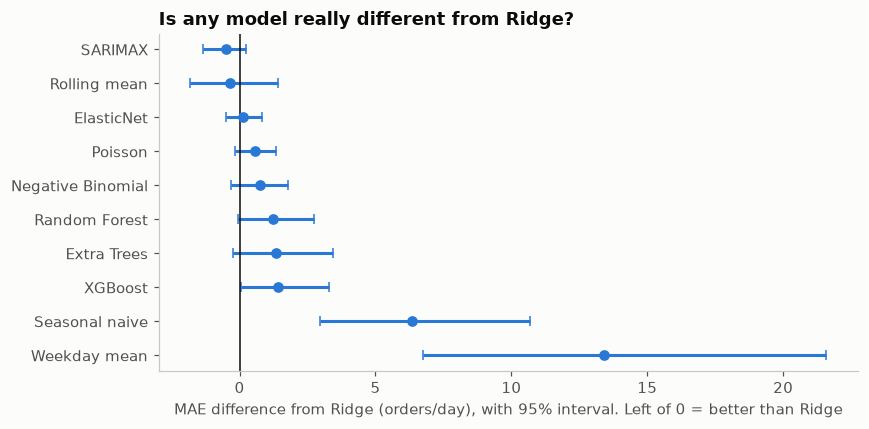

In [7]:
others = table_a.drop(index=ms.INCUMBENT).astype(float).sort_values("delta_MAE")
fig, ax = plt.subplots(figsize=(8, 4))
pos = range(len(others))
ax.errorbar(others["delta_MAE"], pos, xerr=[others["delta_MAE"] - others["ci_low"], others["ci_high"] - others["delta_MAE"]],
            fmt="o", color=C["blue"], capsize=3)
ax.axvline(0, color=C["ink"], lw=1)
ax.set_yticks(list(pos)); ax.set_yticklabels(others.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE difference from Ridge (orders/day), with 95% interval. Left of 0 = better than Ridge")
ax.set_title("Is any model really different from Ridge?")
fig.tight_layout(); fig.savefig(RESULTS / "fig15_mae_difference_vs_ridge.png", dpi=150); plt.show()

### Where each model does well or badly
The test days are mostly dry season, so the rainy and hot columns rest on fewer days. Check the counts before reading them.

In [8]:
ctx = real.loc[preds_a.index]
by_regime = ms.segment_table(y_test, preds_a, ctx["regime"])
by_day = ms.segment_table(y_test, preds_a, pd.Series(np.where(ctx["dow"].isin([4, 5, 6]), "Fri-Sun", "Mon-Thu"), index=ctx.index))
segments = by_regime.join(by_day).loc[table_a.index]
segments.round(2).to_csv(RESULTS / "selection_metrics_by_segment.csv")
print("Days:", by_regime.attrs["days"], by_day.attrs["days"])
segments.round(2)

Days: {'normal': 109, 'rainy': 28, 'hot': 8} {'Mon-Thu': 82, 'Fri-Sun': 63}


,MAE hot,MAE normal,MAE rainy,MAE Fri-Sun,MAE Mon-Thu
SARIMAX,13.71,14.03,22.19,16.92,14.56
Rolling mean,9.64,14.91,20.72,16.98,14.79
Ridge,10.59,14.80,22.68,17.28,15.18
ElasticNet,10.50,15.44,20.81,17.20,15.44
Poisson,11.64,14.85,25.20,17.59,15.96
Negative Binomial,12.50,14.75,26.26,17.78,16.13
Random Forest,11.04,17.04,20.22,17.44,17.23
Extra Trees,10.45,17.41,19.42,17.43,17.40
XGBoost,10.48,17.37,20.10,17.61,17.45
Seasonal naive,15.62,21.93,26.29,25.51,20.05


## 4. Version B: does synthetic training data help?
Same test days and same test features as version A. The extra training days are 2024 plus 1 January 2025, regenerated
from a generator calibrated **only on days before the first forecast**, so no test-period information can reach training.
The team's main dataset is not touched. Synthetic October-December 2025 is never used, because it is future data for
every test day.

In [9]:
real_full = real  # all real days; the cutoff inside the calibration protects the test period
params = ms.calibrate_generator(real_full, first)
print("Calibrated on days before", first.date(), params)
hybrid = ms.build_hybrid_frame(full, real_full, first)
X_b = predict.make_features(hybrid)
y_b = hybrid["order_count"].loc[X_b.index]
preds_b = ms.rolling_backtest(X_b, y_b, ms.make_models(), first).loc[preds_a.index]
preds_b.round(2).to_csv(RESULTS / "selection_backtest_forecasts_hybrid.csv")

def versus(preds_other, label):
    rows = {}
    for m in preds_a.columns:
        ea, eo = y_test - preds_a[m], y_test - preds_other[m]
        stat, p = ms.diebold_mariano(eo, ea) if not np.allclose(ea, eo) else (0.0, 1.0)
        low, high = ms.block_bootstrap_ci(eo.abs() - ea.abs())
        rows[m] = {"MAE real only": ea.abs().mean(), f"MAE {label}": eo.abs().mean(),
                   "delta": (eo.abs() - ea.abs()).mean(), "dm_p": p, "ci_low": low, "ci_high": high}
    out = pd.DataFrame(rows).T
    out["dm_p_holm"] = ms.holm(out["dm_p"].tolist())
    return out.loc[table_a.index]

synth_effect = versus(preds_b, "with synthetic")
synth_effect.round(3).to_csv(RESULTS / "selection_synthetic_training_effect.csv")
synth_effect.round(3)

Calibrated on days before 2025-05-09 {'base': 176.06773478246032, 'r': 59.09855190163657, 'multipliers': {'weekend': 1.0020583182269143, 'rain_mid': 1.0737648908945387, 'rain_heavy': 1.1121959075799983, 'hot': 1.0, 'festival': 0.8970332172358969}}


,MAE real only,MAE with synthetic,delta,dm_p,ci_low,ci_high,dm_p_holm
SARIMAX,15.590,17.910,2.320,0.023,0.079,5.411,0.235
Rolling mean,15.743,15.743,0.000,1.000,0.000,0.000,1.000
Ridge,16.090,18.789,2.699,0.025,0.240,5.959,0.235
ElasticNet,16.204,19.320,3.117,0.003,0.724,6.328,0.028
Poisson,16.669,18.398,1.729,0.142,-0.251,4.629,0.852
Negative Binomial,16.850,18.562,1.712,0.172,-0.215,4.602,0.852
Random Forest,17.324,18.269,0.945,0.276,-0.894,3.254,0.852
Extra Trees,17.416,19.546,2.130,0.028,-0.278,5.180,0.235
XGBoost,17.517,18.870,1.353,0.148,-0.771,3.755,0.852
Seasonal naive,22.421,22.421,0.000,1.000,0.000,0.000,1.000


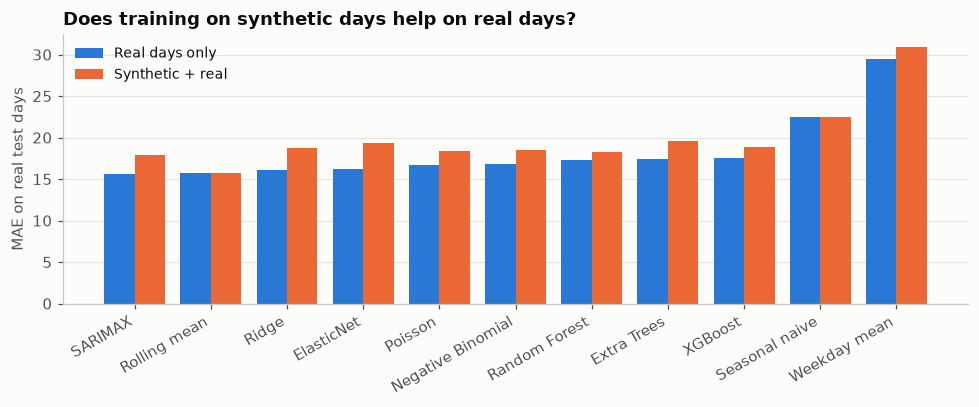

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pos = np.arange(len(synth_effect)); w = 0.4
ax.bar(pos - w / 2, synth_effect["MAE real only"], w, color=C["blue"], label="Real days only")
ax.bar(pos + w / 2, synth_effect["MAE with synthetic"], w, color=C["orange"], label="Synthetic + real")
ax.set_xticks(pos); ax.set_xticklabels(synth_effect.index, rotation=30, ha="right")
ax.set_ylabel("MAE on real test days"); ax.set_title("Does training on synthetic days help on real days?"); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "fig16_synthetic_training_effect.png", dpi=150); plt.show()

## 5. How much does weather help?
The models above use the **actual** weather of the predicted day, which a live system would not know in advance, so
their accuracy is a best case. This run removes same-day weather and monsoon phase. Baselines ignore weather and do
not change.

In [11]:
kept = ms.no_weather_columns(X)
print("Features kept:", ", ".join(kept))
preds_nw = ms.rolling_backtest(X[kept], y, ms.make_models(), first).loc[preds_a.index]
weather_effect = versus(preds_nw, "without weather")
weather_effect.round(3).to_csv(RESULTS / "selection_weather_effect.csv")
weather_effect.round(3)

Features kept: lag1, lag7, roll7, is_fri_sun, is_festival, dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, dow_6


,MAE real only,MAE without weather,delta,dm_p,ci_low,ci_high,dm_p_holm
SARIMAX,15.590,15.322,-0.268,0.270,-0.789,0.172,1.0
Rolling mean,15.743,15.743,0.000,1.000,0.000,0.000,1.0
Ridge,16.090,15.807,-0.283,0.506,-0.936,0.430,1.0
ElasticNet,16.204,15.965,-0.239,0.483,-0.753,0.261,1.0
Poisson,16.669,15.912,-0.757,0.131,-1.528,0.112,1.0
Negative Binomial,16.850,15.890,-0.961,0.093,-1.879,0.111,1.0
Random Forest,17.324,17.235,-0.090,0.835,-0.959,0.707,1.0
Extra Trees,17.416,17.307,-0.108,0.828,-1.346,1.079,1.0
XGBoost,17.517,17.688,0.171,0.753,-1.192,1.254,1.0
Seasonal naive,22.421,22.421,0.000,1.000,0.000,0.000,1.0


## 6. Limits of this evidence
- **One period.** The test days run from about May to September 2025, mostly dry season, from one business in one year.
- **Few rainy and hot days.** Segment results rest on small counts, printed above.
- **Best-case weather.** Models use observed weather, not a forecast.
- **Candidates were not blind.** The earlier 56-day holdout had already shown Ridge ahead on real August-September days,
  and those days are also in this test period. The incumbent was fixed from that result, so the formal tests here are the
  stronger evidence, but the test period is not fully unseen.
- **Version B and the generator.** Its synthetic days are independent draws by design, so they can add evidence about
  calendar and weather effects but not about day-to-day memory.